A weather observation dataset in Sapa (Vietnam) will be used for this midterm project. It is recorded for every 30 minutes from 25 August 2026 through at least 25 September 2026. First we are going to download the dataset from [Kaggle.com](https://www.kaggle.com/datasets/evgenyarbatov/sapa-weather):


In [54]:
import kagglehub
import os
# Download latest version
path = kagglehub.dataset_download("evgenyarbatov/sapa-weather")

# Check the downloaded file
print(os.listdir(path))

Using Colab cache for faster access to the 'sapa-weather' dataset.
['sapa-observations.parquet']


We will import some necessary libraries:

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Let's see how the data looks like:

In [56]:
files = [f for f in os.listdir(path) if f.endswith(".parquet")]

df = pd.read_parquet(os.path.join(path, files[0]))
df.T

,0,1,2,3,4,5,6,7,8,9,...,1501,1502,1503,1504,1505,1506,1507,1508,1509,1510
timestamp,2026-08-25T01:30:00+0000,2026-08-25T02:00:00+0000,2026-08-25T02:30:00+0000,2026-08-25T03:00:00+0000,2026-08-25T03:30:00+0000,2026-08-25T04:00:00+0000,2026-08-25T04:30:00+0000,2026-08-25T05:00:00+0000,2026-08-25T05:30:00+0000,2026-08-25T06:00:00+0000,...,2026-09-25T08:00:00+0000,2026-09-25T08:30:00+0000,2026-09-25T09:00:00+0000,2026-09-25T09:30:00+0000,2026-09-25T10:00:00+0000,2026-09-25T10:30:00+0000,2026-09-25T11:00:00+0000,2026-09-25T11:30:00+0000,2026-09-25T12:00:00+0000,2026-09-25T12:30:00+0000
timestamp_local,2026-08-25T08:30:00+07:00,2026-08-25T09:00:00+07:00,2026-08-25T09:30:00+07:00,2026-08-25T10:00:00+07:00,2026-08-25T10:30:00+07:00,2026-08-25T11:00:00+07:00,2026-08-25T11:30:00+07:00,2026-08-25T12:00:00+07:00,2026-08-25T12:30:00+07:00,2026-08-25T13:00:00+07:00,...,2026-09-25T15:00:00+07:00,2026-09-25T15:30:00+07:00,2026-09-25T16:00:00+07:00,2026-09-25T16:30:00+07:00,2026-09-25T17:00:00+07:00,2026-09-25T17:30:00+07:00,2026-09-25T18:00:00+07:00,2026-09-25T18:30:00+07:00,2026-09-25T19:00:00+07:00,2026-09-25T19:30:00+07:00
lat,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,...,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402,22.3402
lon,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,...,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442,103.8442
site_id,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,...,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town,sapa-town
source,openweather,openweather,openweather,openweather,openweather,openweather,openweather,openweather,openweather,openweather,...,openweather,openweather,openweather,openweather,openweather,openweather,openweather,openweather,openweather,openweather
schema_version,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
weather_temp,24.07,24.08,24.06,25.42,25.4,24.97,24.81,24.81,26.16,26.34,...,22.24,22.24,21.51,19.98,19.98,18.07,18.07,17.64,17.65,17.01
weather_feels_like,24.15,24.16,24.14,25.51,25.48,25.19,25.12,25.12,26.16,26.34,...,22.32,22.32,21.65,20.25,20.25,18.28,18.28,17.84,17.85,17.17
weather_humidity,62,62,62,57,57,64,68,68,60,60,...,69,69,74,85,85,90,90,91,91,92


There are 20 columns in total, in which there are 5 columns only showing the recorded location and the data source information. They are

```
["lat", "lon", "site_id", "source", "schema_version"]
```
which denote the latitude, the longtitude, the id of recorded location, the data provider, and the version of the data structure, respectively.

Our objective is to predict whether it is rain in Sapa at a specific time. Therfore,these columns do not affect our prediction. We will delete these columns. Moreover, to achieve the objective, we also delete

```
["weather_rain_1h", "weather_id", "weather_description"	]
```

We also delete all the timestamp columns because they can be treated as indexes which we already had






In [57]:
df = df.drop(columns=["timestamp","lat", "lon", "site_id", "source", "schema_version", "weather_rain_1h", "weather_id", "weather_description", "timestamp_local"])
df.T

,0,1,2,3,4,5,6,7,8,9,...,1501,1502,1503,1504,1505,1506,1507,1508,1509,1510
weather_temp,24.07,24.08,24.06,25.42,25.4,24.97,24.81,24.81,26.16,26.34,...,22.24,22.24,21.51,19.98,19.98,18.07,18.07,17.64,17.65,17.01
weather_feels_like,24.15,24.16,24.14,25.51,25.48,25.19,25.12,25.12,26.16,26.34,...,22.32,22.32,21.65,20.25,20.25,18.28,18.28,17.84,17.85,17.17
weather_humidity,62,62,62,57,57,64,68,68,60,60,...,69,69,74,85,85,90,90,91,91,92
weather_pressure,1005,1005,1005,1005,1005,1005,1004,1004,1003,1003,...,1011,1011,1011,1011,1011,1012,1012,1013,1013,1014
weather_wind_speed,0.73,0.73,0.73,0.76,0.76,0.79,0.1,0.1,0.68,0.86,...,1.46,1.46,1.49,1.31,1.31,0.63,0.63,0.56,0.56,0.64
weather_wind_deg,13,13,13,51,51,83,169,169,281,293,...,83,83,85,77,77,89,89,145,145,120
weather_wind_gust,1.95,1.95,1.95,2.59,2.59,2.26,1.82,1.82,1.9,2.14,...,1.1,1.1,1.6,1.31,1.31,0.98,0.98,1.13,1.13,1.11
weather_clouds,76,76,76,61,61,56,57,57,58,40,...,99,99,96,95,95,90,90,87,87,42
weather_visibility,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,...,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0,10000.0
weather_main,Clouds,Rain,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,...,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds,Clouds


Our target column is "weather_main". However, the column has 3 variable while what we need are "rain" and "not rain". Therefore we will modify the columns.

In [58]:
print ("The number of unique values in 'weather_main' columns:", df['weather_main'].nunique())

df['weather_main'] = df['weather_main'].str.lower()

k = list(np.unique(df['weather_main'].values))
print(k)

dictionary = {}
for i in k:
  if i != "rain":
    dictionary[i] = 0
  else: dictionary["rain"] = 1

df['weather_main'] = df['weather_main'].map(dictionary)
print(df['weather_main'])



The number of unique values in 'weather_main' columns: 3
['clear', 'clouds', 'rain']
0       0
1       1
2       0
3       0
4       0
       ..
1506    0
1507    0
1508    0
1509    0
1510    0
Name: weather_main, Length: 1511, dtype: int64


The remaining features are:
* weather_temp: the temperature at that time
* weather_feels_like: the temperature that human feels at that time (usually based on humidity and the wind speed)
* weather_humidity: the humidity of that time
* weather_pressure: the atmosphere pressure
* weather_wind_speed: the wind speed
* weather_wind_deg: the wind direction ($0^∘$- $360^∘$ with $0^∘$ is the north and $90^∘$ is the west).
* weather_wind_gust: the wind gust speed
* weather_clouds: the cloudiness (%)
* weather_visibility: The maximum distance at which objects can be clearly seen

We will now need to clean missing values

In [59]:
df.isnull().sum()
for i in df.columns:
  if df[i].isnull().sum() >0: df[i]=df[i].fillna(df[i].mean())


We will establish a baseline model first (Logistic_Regression)

In [70]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

target_train = df_train.weather_main.values
target_val = df_val.weather_main.values
target_test = df_test.weather_main.values
target_full_train = df_full_train.weather_main.values

df_full_train.reset_index(drop=True, inplace=True)
df_train.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)
del df_train['weather_main']
del df_val['weather_main']
del df_test['weather_main']
#del df_full_train['weather_main']



dv = DictVectorizer(sparse=True)
model = LogisticRegression(solver='liblinear', random_state=1)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))

model.fit(X_train, target_train)
y_pred = model.predict_proba(X_val).T[1]
print(roc_auc_score(target_val, y_pred))

# Checking overfitting
print(roc_auc_score(target_train, model.predict_proba(X_train).T[1]))


0.7691804504251939
0.7802033492822966


The baseline model performed quite well without overfitting. We will see if we can improve the data.

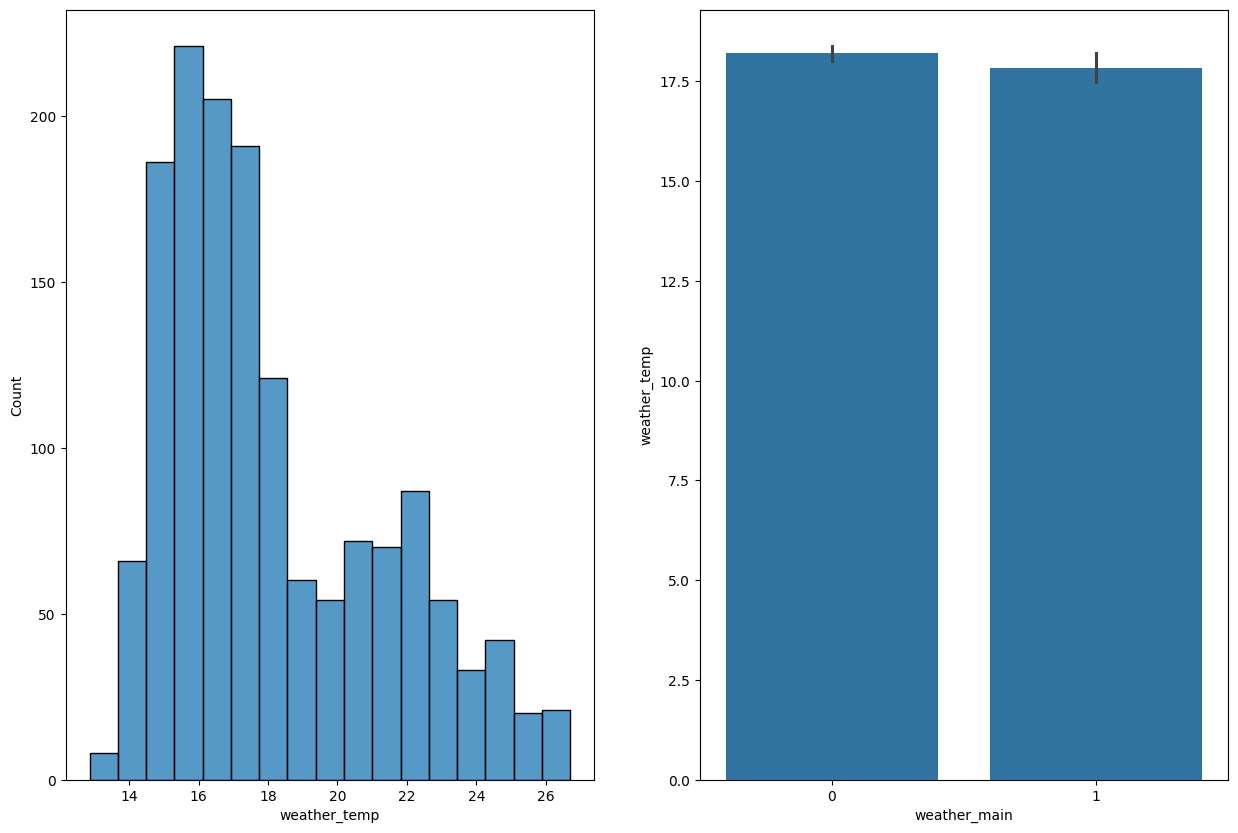

The value range of weather_temp:[ 12.86 , 26.7 ]
The value range of weather_clouds:[ 0 , 100 ]
The value range of weather_main:[ 0 , 1 ]
The value range of weather_visibility:[ 65.0 , 10000.0 ]
              weather_temp  weather_clouds  weather_wind_speed  \
weather_main                                                     
0                    12.86               0                0.01   
1                    14.17               8                0.06   

              weather_visibility  
weather_main                      
0                           65.0  
1                          144.0  


In [61]:
plt.figure(figsize=(15, 10))
plt.subplot(1, 2, 1)
sns.histplot(df["weather_temp"])
plt.subplot(1, 2, 2)
#sns.lineplot(y= df["weather_temp"], x= df["timestamp"])
sns.barplot(x= df["weather_main"], y= df["weather_temp"])
plt.show()
print("The value range of weather_temp:[", min(df['weather_temp']) ,",", max(df['weather_temp']),"]")
print("The value range of weather_clouds:[", min(df['weather_clouds']) ,",", max(df['weather_clouds']),"]")
print("The value range of weather_main:[", min(df['weather_main']) ,",", max(df['weather_main']),"]")
print("The value range of weather_visibility:[", min(df['weather_visibility']) ,",", max(df['weather_visibility']),"]")
print(df.groupby('weather_main')[["weather_temp", "weather_clouds", "weather_wind_speed", "weather_visibility" ]].min())

The temperature of the weather fluctuates a lot from $12.86^∘C$ to $26.7^∘C$. The min values of weather_temp and weather_clouds so that it can rains are $14.17^∘$C and 8%. With the check of the value range of these features, we claim that there is no rain below such values. This motivates us to use the decision_tree model with the main feature lying on weather_clouds and weather_temp instead of doing feature engineering.

We will check the above assumption using $\texttt{feature_importances_()}$

In [62]:
from sklearn.tree import DecisionTreeClassifier

model_1 = DecisionTreeClassifier(max_features = 4, max_depth = 4, random_state = 1)
model_1.fit(X_train, target_train)
y_pred = model_1.predict_proba(X_val).T[1]
print("auc on val data",roc_auc_score(target_val, y_pred))

# Checking overfitting
print("auc on train data",roc_auc_score(target_train, model_1.predict_proba(X_train).T[1]))
importance = (pd.DataFrame(list(zip(model_1.feature_importances_, dv.get_feature_names_out())), columns = ["importance", "feature"]))
print ((importance))
print()
print (importance.feature[importance.importance > 0])


auc on val data 0.7817960938230072
auc on train data 0.8592559365585681
   importance             feature
0    0.082275      weather_clouds
1    0.000000  weather_feels_like
2    0.191455    weather_humidity
3    0.210283    weather_pressure
4    0.160290        weather_temp
5    0.065307  weather_visibility
6    0.093954    weather_wind_deg
7    0.087761   weather_wind_gust
8    0.108676  weather_wind_speed

0        weather_clouds
2      weather_humidity
3      weather_pressure
4          weather_temp
5    weather_visibility
6      weather_wind_deg
7     weather_wind_gust
8    weather_wind_speed
Name: feature, dtype: object


The code above shows that decision tree perform better then logistic regression model and eventhough weather_clouds and weather_temp are important but weather_pressure and weather_humidity are more important.

Now we will try other models

In [63]:
from sklearn.ensemble import RandomForestClassifier
model_2 = RandomForestClassifier(n_estimators=100, random_state=1, max_depth = 6)
model_2.fit(X_train, target_train)
y_pred = model_2.predict_proba(X_val).T[1]
print("auc on val data",roc_auc_score(target_val, y_pred))

#Overfitting check
print("auc on train data",roc_auc_score(target_train, model_2.predict_proba(X_train).T[1]))

print()
import xgboost as xgb
xgb_params = {
        "eta" :0.3, #How fast the model learn
        "max_depth" :7,
        "min_child_weight":1,
        "objective": "binary:logistic",
        "nthread":8,
        "seed": 1,
        "verbosity":1,
        "eval_metric":"auc"
    }

# Convert datasets to DMatrix
dtrain = xgb.DMatrix(X_train, label=target_train)
dval = xgb.DMatrix(X_val, label=target_val)

model_3 = xgb.train(xgb_params, dtrain, num_boost_round = 100, verbose_eval =5, evals= [(dtrain, "train"), (dval, "val")])
y_pred = model_3.predict(dval)
print("auc on val data",roc_auc_score(target_val, y_pred))

auc on val data 0.8354359405663022
auc on train data 0.989134768740032

[0]	train-auc:0.93952	val-auc:0.78670
[5]	train-auc:0.98819	val-auc:0.80432
[10]	train-auc:0.99519	val-auc:0.81707
[15]	train-auc:0.99694	val-auc:0.80735
[20]	train-auc:0.99753	val-auc:0.80633
[25]	train-auc:0.99783	val-auc:0.81100
[30]	train-auc:0.99807	val-auc:0.80894
[35]	train-auc:0.99824	val-auc:0.80941
[40]	train-auc:0.99829	val-auc:0.81063
[45]	train-auc:0.99829	val-auc:0.81530
[50]	train-auc:0.99833	val-auc:0.81474
[55]	train-auc:0.99831	val-auc:0.81717
[60]	train-auc:0.99833	val-auc:0.81791
[65]	train-auc:0.99834	val-auc:0.81754
[70]	train-auc:0.99835	val-auc:0.81623
[75]	train-auc:0.99835	val-auc:0.81819
[80]	train-auc:0.99836	val-auc:0.81913
[85]	train-auc:0.99836	val-auc:0.81810
[90]	train-auc:0.99836	val-auc:0.81838
[95]	train-auc:0.99836	val-auc:0.81922
[99]	train-auc:0.99836	val-auc:0.82044
auc on val data 0.8204373423044578


On a random try, the random_forest model perform best. So we take that model and perform parameter tuning for the model (n_estimator and max_depth).

In [64]:
table = []

for i in np.linspace(2,65,10):
  for j in np.linspace(1,16,16):
    model_final = RandomForestClassifier(n_estimators=int(i), random_state=1, max_depth = int(j))
    model_final.fit(X_train, target_train)
    y_pred = model_final.predict_proba(X_val).T[1]
    table.append([i,j,roc_auc_score(target_val, y_pred)])
table=pd.DataFrame(table, columns=["n_estimators", "max_depth", "auc"])
print(table)





     n_estimators  max_depth       auc
0             2.0        1.0  0.726334
1             2.0        2.0  0.745678
2             2.0        3.0  0.767311
3             2.0        4.0  0.755210
4             2.0        5.0  0.725680
..            ...        ...       ...
155          65.0       12.0  0.824175
156          65.0       13.0  0.826371
157          65.0       14.0  0.830483
158          65.0       15.0  0.833380
159          65.0       16.0  0.828334

[160 rows x 3 columns]


In [65]:
for i in range (1, len(table)):
  if table.auc.iloc[i] == table.auc.max():
    print(table.n_estimators.iloc[i], table.max_depth.iloc[i])

23.0 8.0


The best auc is achieved at n_estimators = 23 and max_depth = 8

Visualize the table into a heatmap also helps

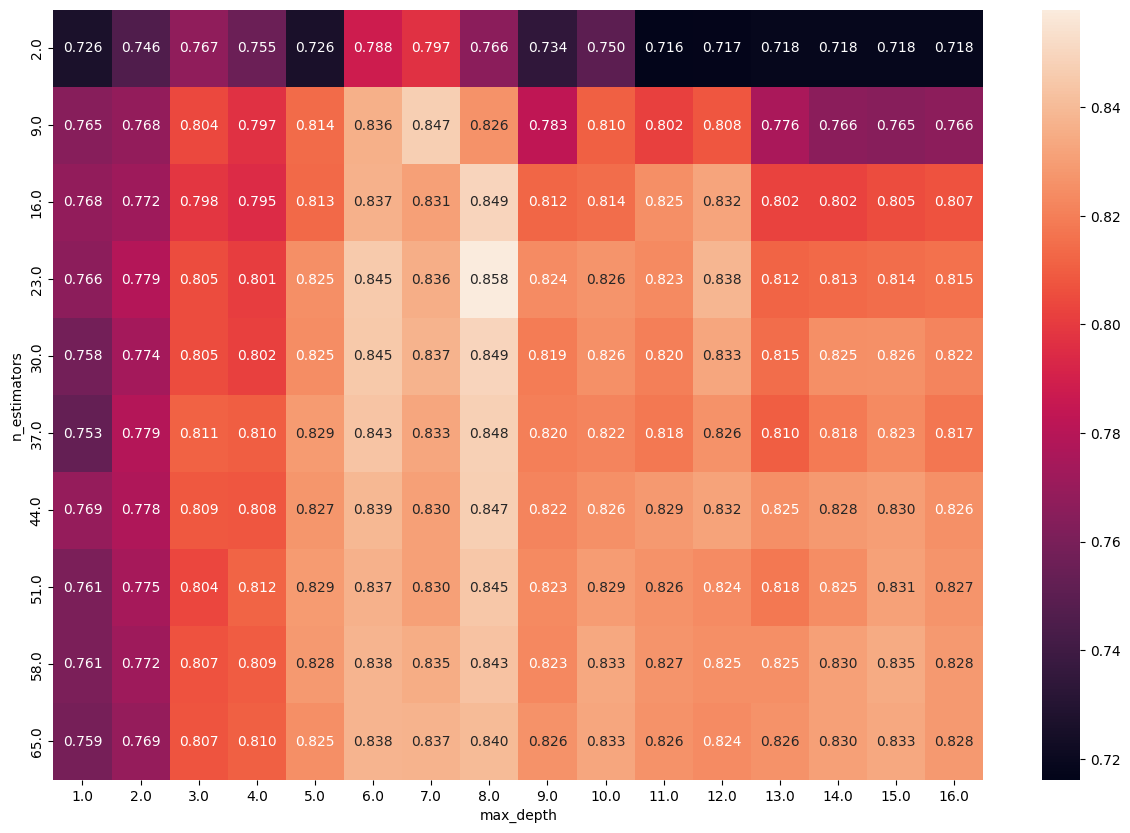

In [66]:
table = table.pivot(index = "n_estimators", columns = "max_depth", values = "auc")
plt.figure(figsize=(15, 10))
sns.heatmap(table, annot = True, fmt = ".3f")
plt.show()




We have got our final model. Now we perform a full train with K-fold.



In [77]:
# Overfitting check
final_model = RandomForestClassifier(n_estimators=23, random_state=1, max_depth = 8)
final_model.fit(X_train, target_train)
y_pred = final_model.predict_proba(X_train).T[1]
print("auc on train data",roc_auc_score(target_train, y_pred))

auc on train data 0.996588693957115


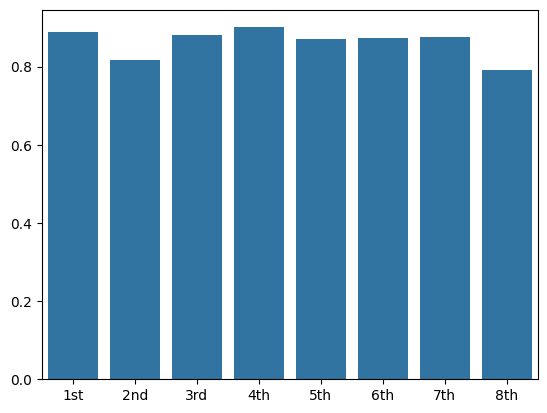

Mean value: 0.8620507257043664


In [80]:
from sklearn.model_selection import KFold
final_model = RandomForestClassifier(n_estimators=23, random_state=1, max_depth = 8)
kfold = KFold(n_splits=8, shuffle=True, random_state=1)
scores = []
for full_train_index, val_index in (kfold.split(df_full_train)):
  full_train = df_full_train.iloc[full_train_index].reset_index(drop=True)
  val = df_full_train.iloc[val_index].reset_index(drop=True)
  target_full_train = full_train.weather_main.values
  target_val = val.weather_main.values
  del full_train['weather_main']
  del val['weather_main']

  X_full_train = dv.transform(full_train.to_dict(orient='records'))
  X_val = dv.transform(val.to_dict(orient='records'))
  final_model.fit(X_full_train, target_full_train)
  y_pred = final_model.predict_proba(X_val).T[1]
  scores.append(roc_auc_score(target_val, y_pred))
sns.barplot(x = ["1st", "2nd", "3rd","4th", "5th", "6th", "7th", "8th" ], y = scores)
plt.show()

print ("Mean value:", np.mean(scores))

Now we test our model in the test data

In [82]:
X_test = dv.transform(df_test.to_dict(orient='records'))
y_pred = final_model.predict_proba(X_test).T[1]
print("auc on test data",roc_auc_score(target_test, y_pred))

auc on test data 0.8928970396574194


In [85]:
print (df_test.T)

                         0         1         2         3        4         5    \
weather_temp           16.74     14.50     20.59     19.83    15.32     17.83   
weather_feels_like     16.72     14.49     20.72     19.91    15.49     17.78   
weather_humidity       86.00     95.00     77.00     78.00    99.00     81.00   
weather_pressure     1013.00   1017.00   1012.00   1011.00  1014.00   1008.00   
weather_wind_speed      0.38      1.13      1.96      2.18     0.92      0.86   
weather_wind_deg       42.00     48.00     69.00     54.00    54.00    323.00   
weather_wind_gust       0.80      2.40      2.53      2.20     1.36      1.71   
weather_clouds         49.00    100.00     64.00     86.00    97.00     48.00   
weather_visibility  10000.00  10000.00  10000.00  10000.00   527.00  10000.00   

                         6         7         8         9    ...      293  \
weather_temp           16.63     26.66     17.44     17.44  ...    15.49   
weather_feels_like     16.59     26.6

The final train is also written in $\texttt{train.py}$ file.